Importations

In [60]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

Telecharger dfSet

In [61]:
df = pd.read_csv('../data/student_mental_health.csv')

In [62]:
df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [63]:
df.describe()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


In [64]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [65]:
print("Dimensions :", df.shape)

Dimensions : (2000, 17)


In [66]:
print("Valeurs manquantes :")

df.isna().sum()

Valeurs manquantes :


Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

In [67]:
print("Nombre de doublons :", df.duplicated().sum())

Nombre de doublons : 0


In [68]:
df.columns

Index(['Student_ID', 'Age', 'Gender', 'Year_of_Study', 'Sleep_Hours',
       'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours',
       'Screen_Time_Hours', 'Physical_Activity', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate', 'Part_Time_Job', 'Diet_Quality',
       'Previous_Mental_Health_History', 'Mental_Health_Risk'],
      dtype='str')

In [69]:
unique_columns = df[['Age', 'Gender','Physical_Activity','Part_Time_Job','Diet_Quality','Previous_Mental_Health_History','Mental_Health_Risk']]

In [70]:
for col in unique_columns:
    print(col, ":", df[col].unique())

Age : [22 21 24 20 23 17 19 18 25 26 27 29 28]
Gender : <ArrowStringArray>
['Male', 'Female', 'Non-binary']
Length: 3, dtype: str
Physical_Activity : <ArrowStringArray>
['Moderate', 'Low', 'High']
Length: 3, dtype: str
Part_Time_Job : <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
Diet_Quality : <ArrowStringArray>
['Poor', 'Average', nan, 'Good']
Length: 4, dtype: str
Previous_Mental_Health_History : <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
Mental_Health_Risk : <ArrowStringArray>
['High', 'Medium', 'Low']
Length: 3, dtype: str


In [71]:
df["Mental_Health_Risk"].value_counts()

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64

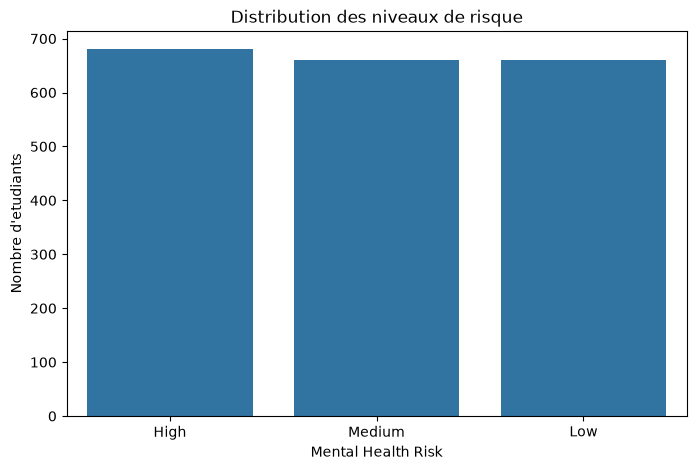

In [72]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Mental_Health_Risk")

plt.title("Distribution des niveaux de risque")
plt.xlabel("Mental Health Risk")
plt.ylabel("Nombre d'etudiants")
plt.show()

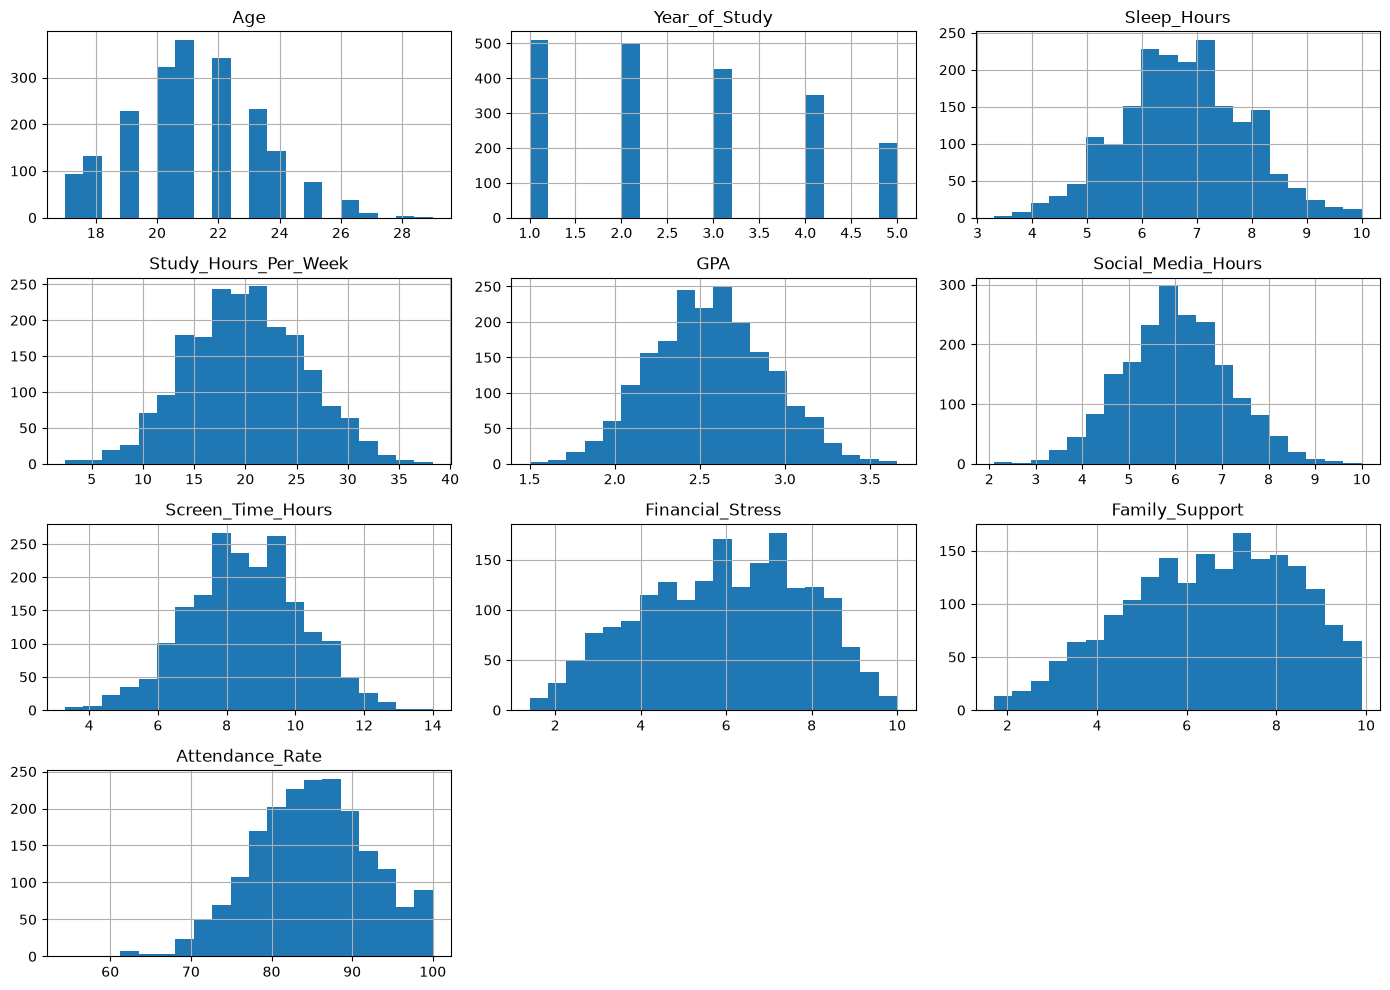

In [73]:
numeric_features = df.select_dtypes(include=np.number).columns

df[numeric_features].hist(figsize=(14, 10), bins=20)
plt.tight_layout()
plt.show()

C:\Users\Youcode\AppData\Local\Temp\ipykernel_15956\1804551245.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns.drop("Student_ID", errors="ignore")


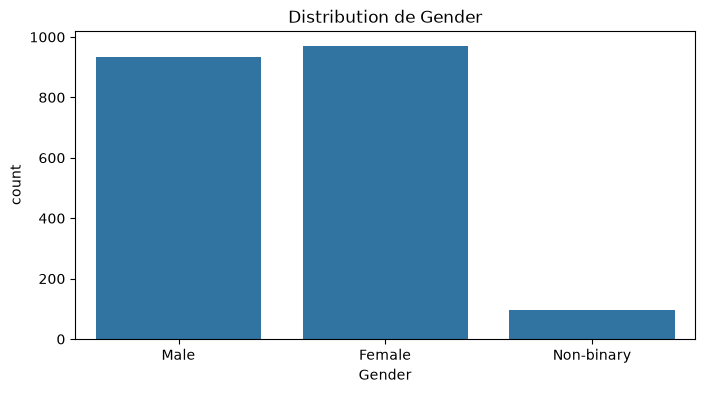

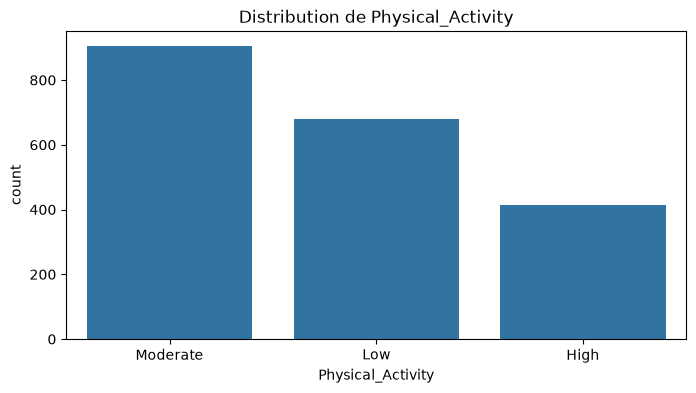

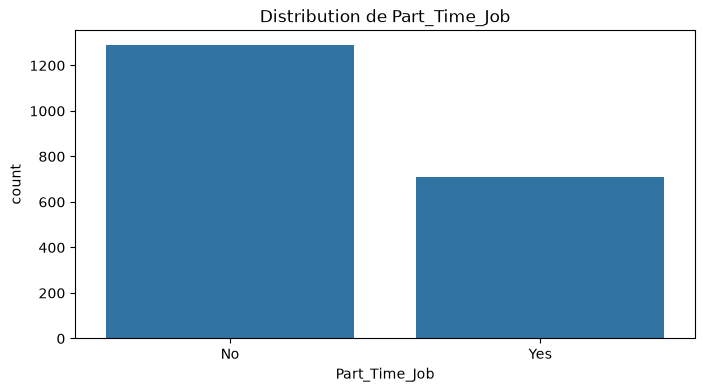

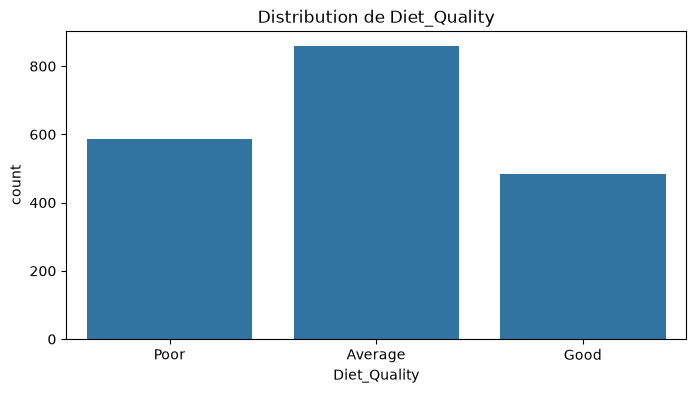

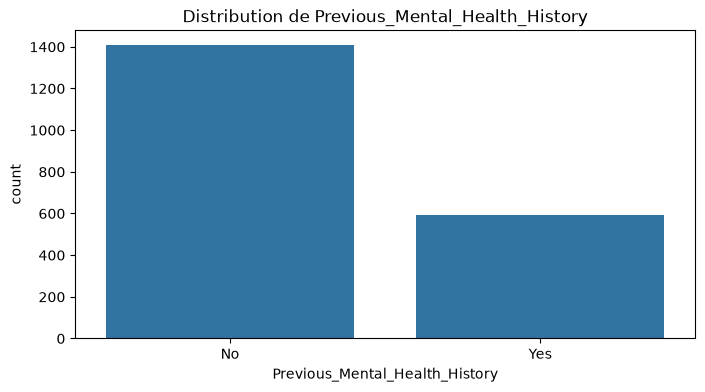

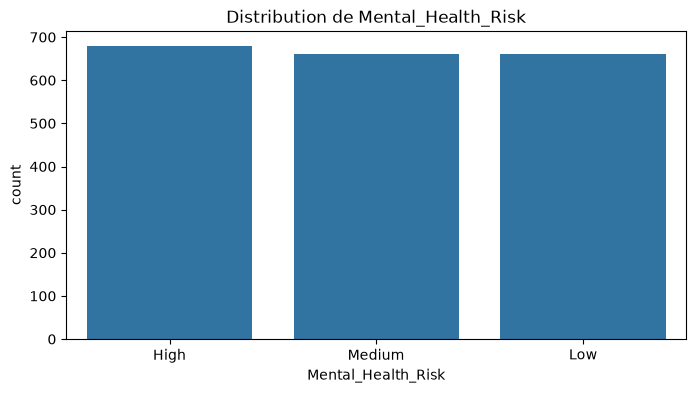

In [74]:
categorical_cols = df.select_dtypes(include="object").columns.drop("Student_ID", errors="ignore")


for col in categorical_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col)
    plt.title("Distribution de " + col)
    plt.show()

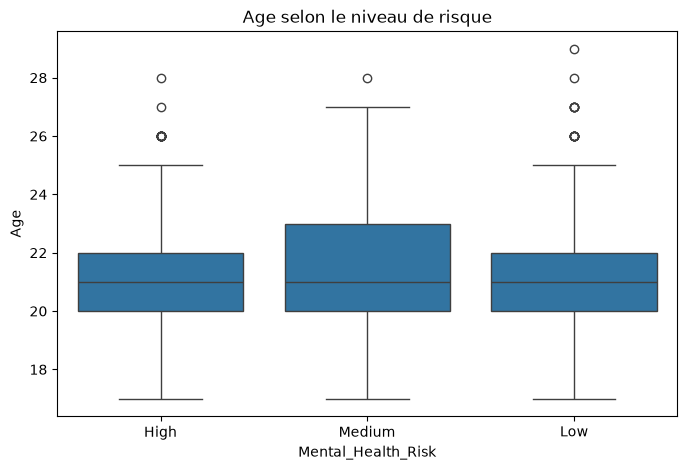

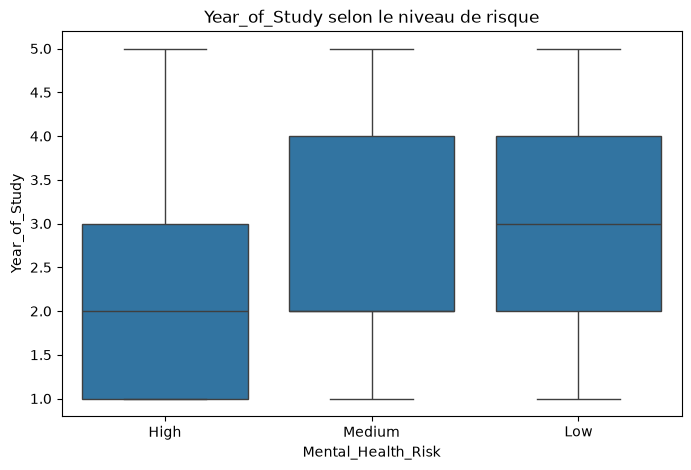

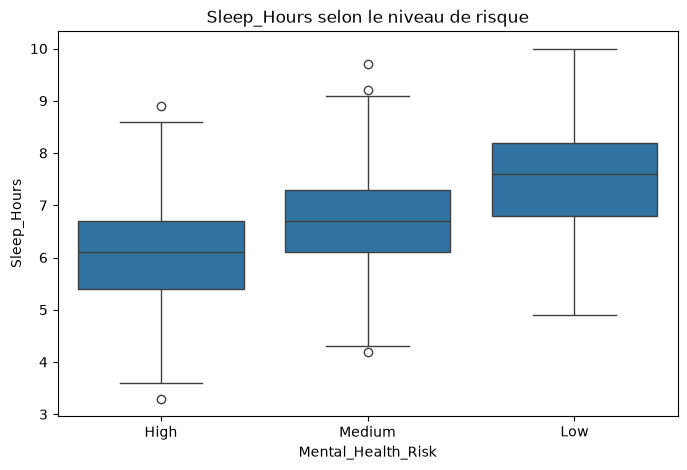

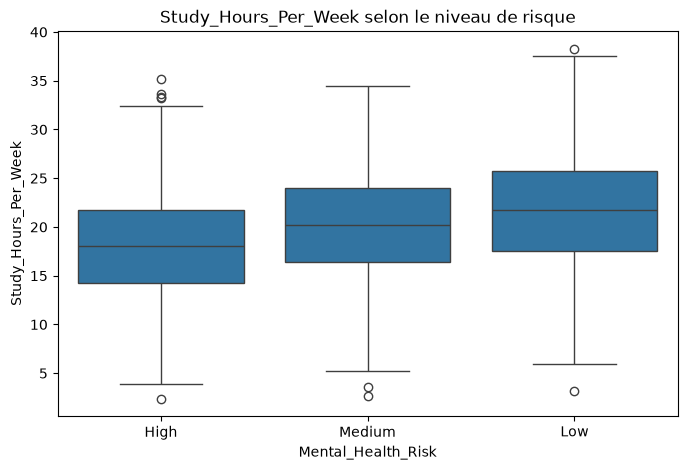

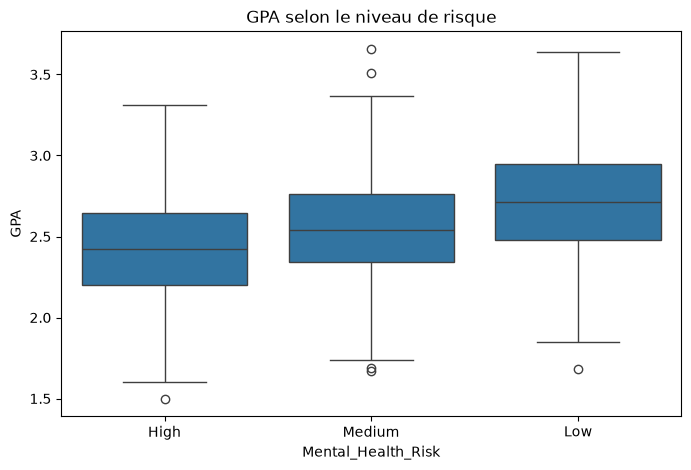

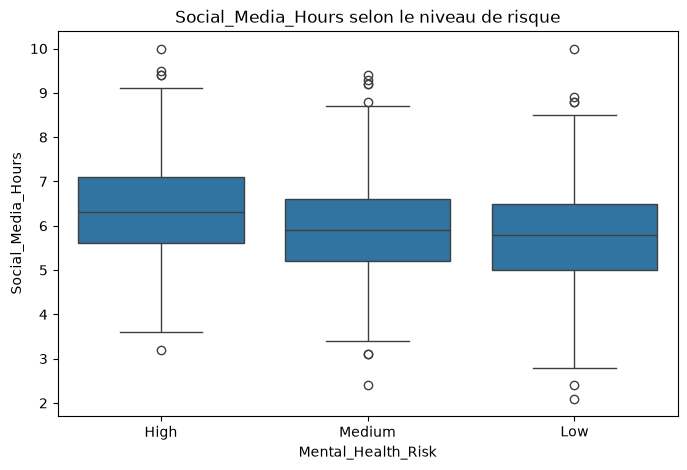

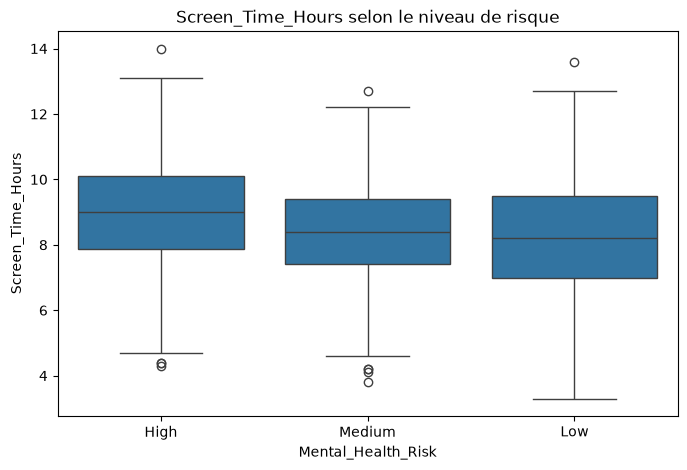

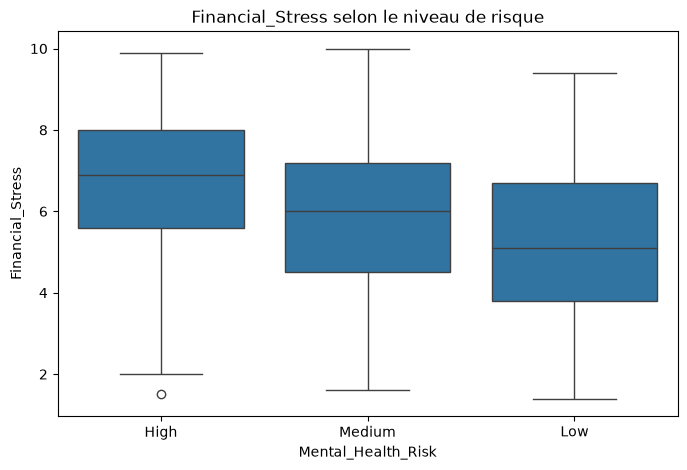

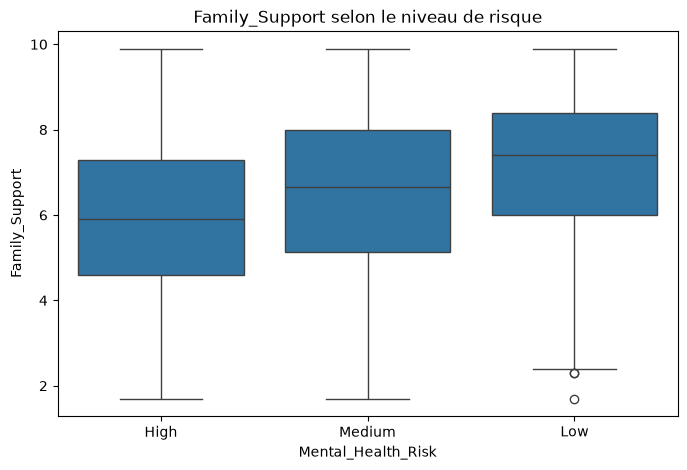

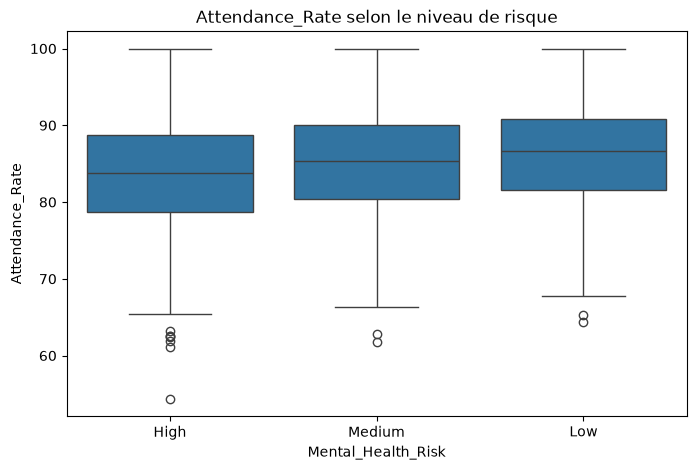

In [75]:
numeric_features.drop("Year_of_Study")
for col in numeric_features:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x="Mental_Health_Risk", y=col)
    plt.title(col + " selon le niveau de risque")
    plt.show()

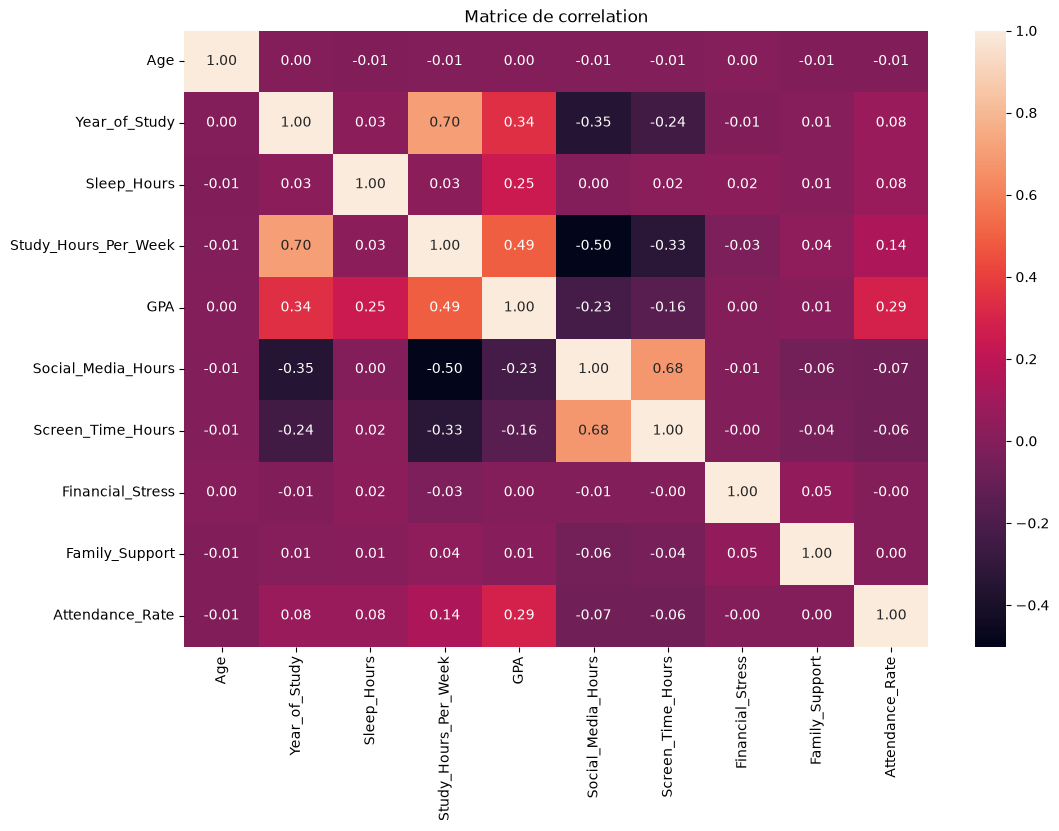

In [76]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    fmt=".2f"
)

plt.title("Matrice de correlation")
plt.show()

In [77]:
df.groupby("Mental_Health_Risk")["Age"].mean()

Mental_Health_Risk
High      21.138235
Low       21.112121
Medium    21.143939
Name: Age, dtype: float64

Detection des valeurs aberrantes avec IQR

In [78]:
for col in numeric_features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()
    print(col, ":", count)

Age : 4
Year_of_Study : 0
Sleep_Hours : 2
Study_Hours_Per_Week : 7
GPA : 9
Social_Media_Hours : 20
Screen_Time_Hours : 7
Financial_Stress : 0
Family_Support : 0
Attendance_Rate : 12


Boxplots des variables numeriques

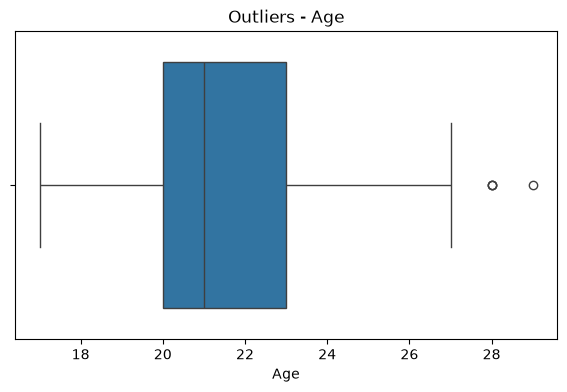

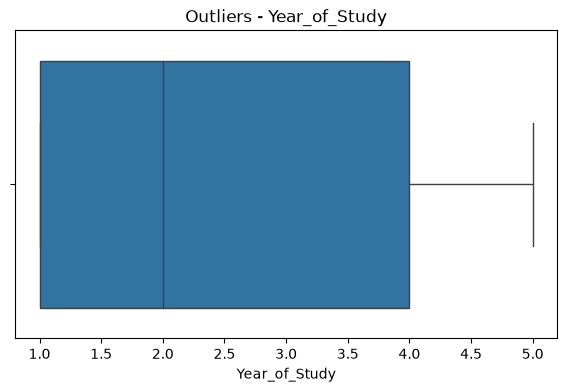

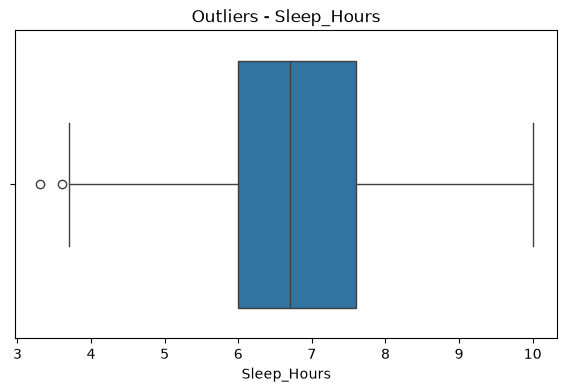

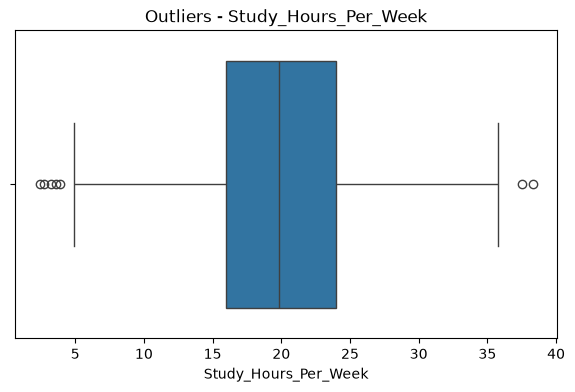

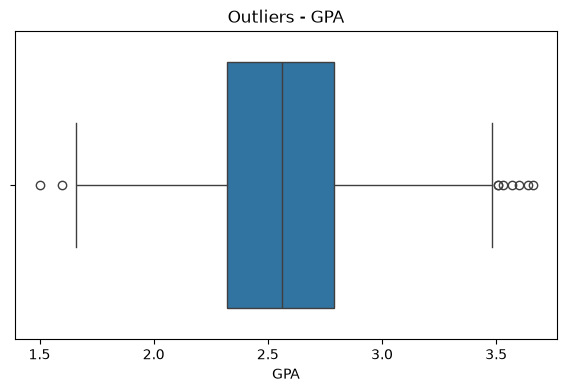

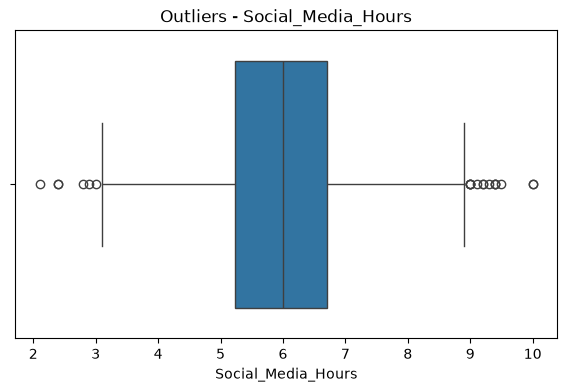

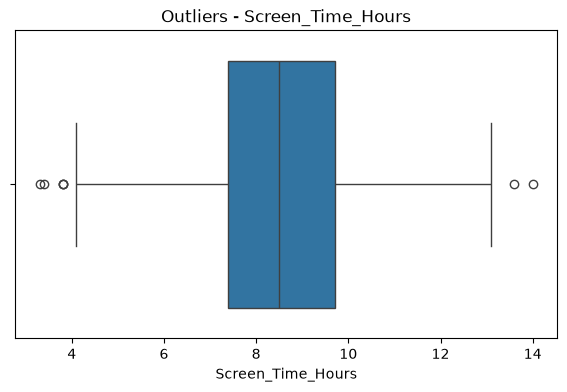

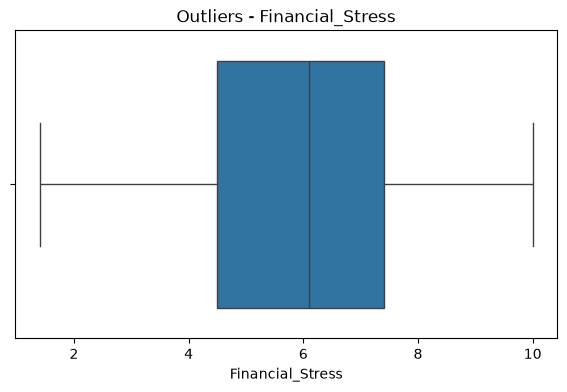

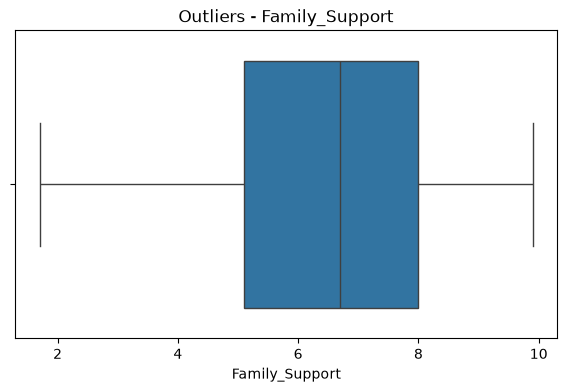

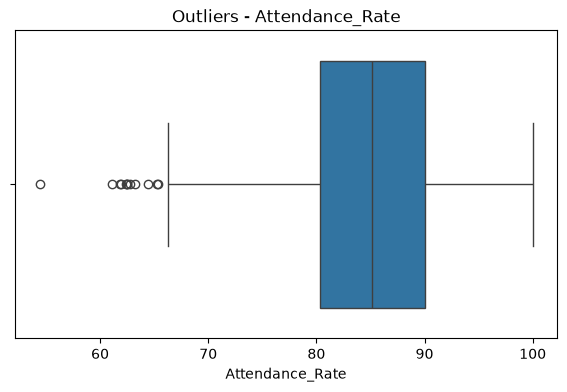

In [79]:
for col in numeric_features:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=df[col])
    plt.title("Outliers - " + col)
    plt.show()

Preparation des donnees

In [81]:
df = df.dropna(subset=["Mental_Health_Risk"])

X = df.drop(columns=["Mental_Health_Risk", "Student_ID"])
y = df["Mental_Health_Risk"]

print(X.shape)
print(y.shape)

(2000, 15)
(2000,)


In [82]:
numeric_features = X.select_dtypes(include=np.number).columns
categorical_features = X.select_dtypes(exclude=np.number).columns

print("Numerical features :", list(numeric_features))
print("Categorical features :", list(categorical_features))

Numerical features : ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
Categorical features : ['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']


split de donnes

In [83]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train :", X_train.shape)
print("X_test :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test :", y_test.shape)

X_train : (1600, 15)
X_test : (400, 15)
y_train : (1600,)
y_test : (400,)


***Preprocessing des variables numeriques***

In [84]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

***Preprocessing des variables categorielles***

In [85]:
from sklearn.preprocessing import OneHotEncoder

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

***Creation du preprocessor***

In [86]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])